In [ ]:
import sys
from pathlib import Path

# Add root directory to path
sys.path.append(str(Path.cwd().parent))

from src.data_loader import load_scada_data, filter_operational_data
from src.plotting import plot_multi_turbine_power_curves
import matplotlib.pyplot as plt

# 1. Dictionary to hold multi-turbine datasets
turbine_data = {}
turbine_ids = ['1', '2', '3', '4', '5', '6']  # Adjust based on your filenames (e.g., Kelmarsh_SCADA_2019_T1.csv)

for t_id in turbine_ids:
    file_path = Path(f"../data/Turbine_Data_Kelmarsh_{t_id}_2020-01-01_-_2021-01-01.csv")
    try:
        df = load_scada_data(file_path)
        turbine_data[f"Turbine {t_id}"] = filter_operational_data(df)
    except FileNotFoundError:
        print(f"File for {t_id} not found. Skipping...")

# 2. Plot comparison if data was successfully loaded
if turbine_data:
    fig, ax = plot_multi_turbine_power_curves(
        turbine_data, 
        wind_speed_col='Wind speed (m/s)', 
        power_col='Power (kW)'
    )
    plt.show()
else:
    print("Please ensure your multi-turbine CSV files are placed in the data/ folder.")

Generating diagnostic dashboard for Turbine 1...


c:\Users\farra\Documents\Projects\kelmarsh-scada-analysis\src\plotting.py:268: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


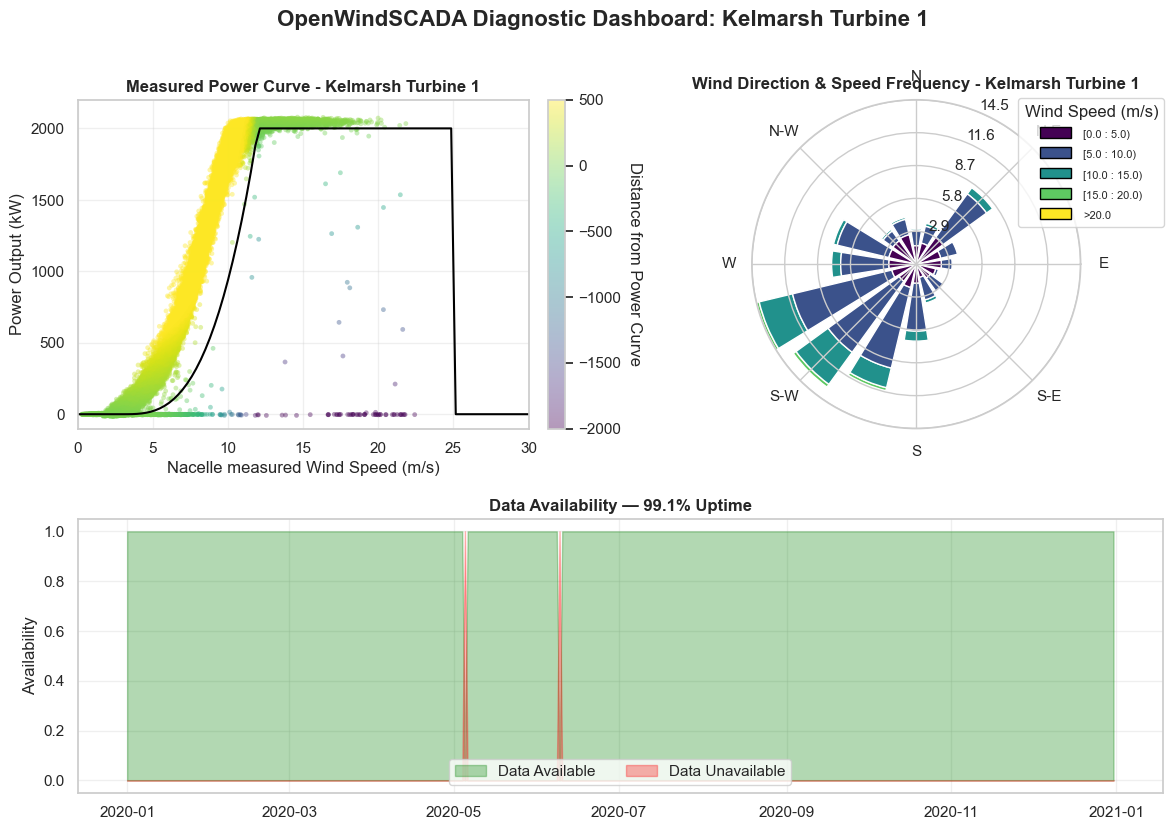

Generating diagnostic dashboard for Turbine 2...


c:\Users\farra\Documents\Projects\kelmarsh-scada-analysis\src\plotting.py:268: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


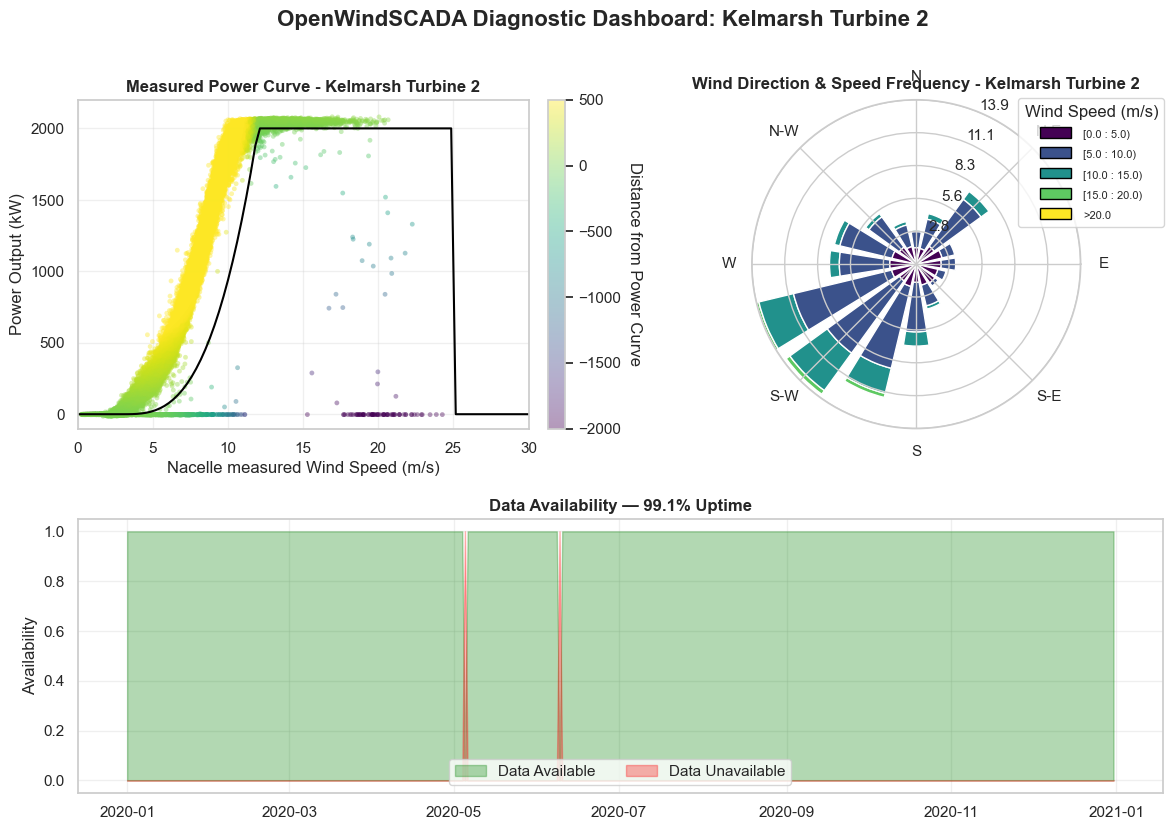

Generating diagnostic dashboard for Turbine 3...


c:\Users\farra\Documents\Projects\kelmarsh-scada-analysis\src\plotting.py:268: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


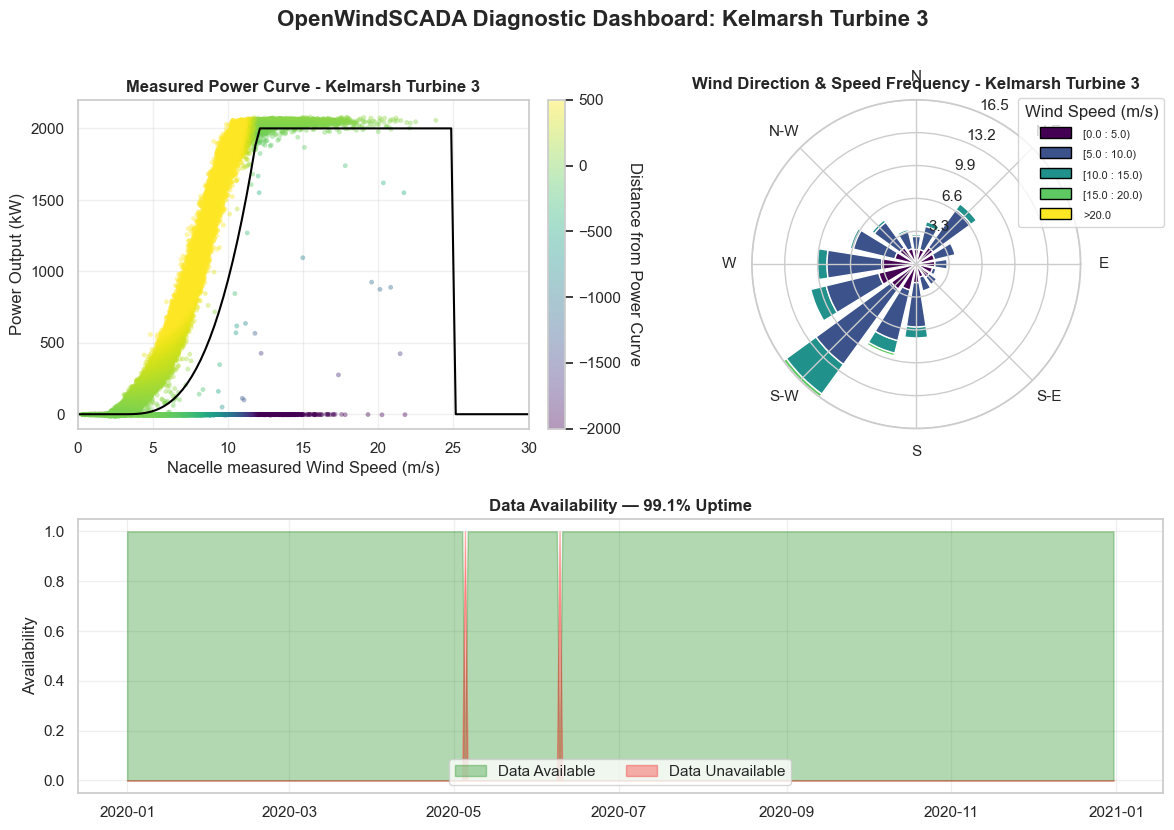

Generating diagnostic dashboard for Turbine 4...


c:\Users\farra\Documents\Projects\kelmarsh-scada-analysis\src\plotting.py:268: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


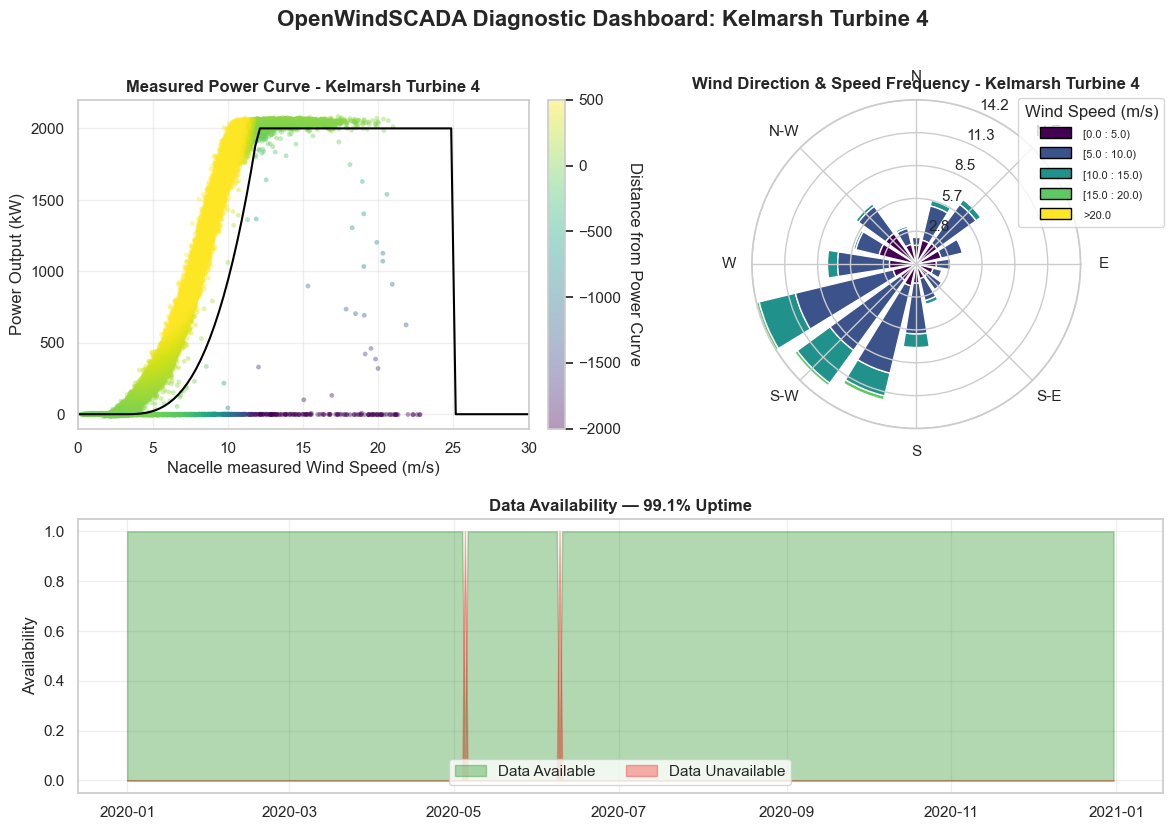

Generating diagnostic dashboard for Turbine 5...


c:\Users\farra\Documents\Projects\kelmarsh-scada-analysis\src\plotting.py:268: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


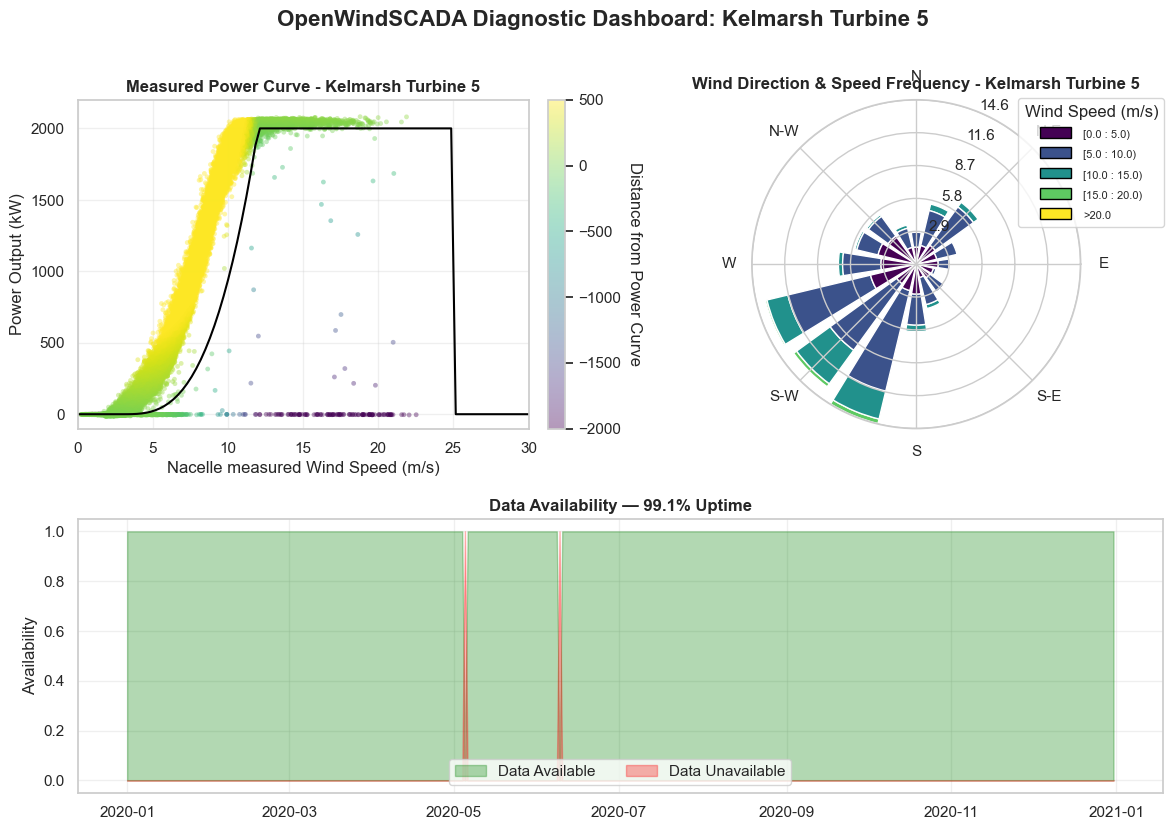

Generating diagnostic dashboard for Turbine 6...


c:\Users\farra\Documents\Projects\kelmarsh-scada-analysis\src\plotting.py:268: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


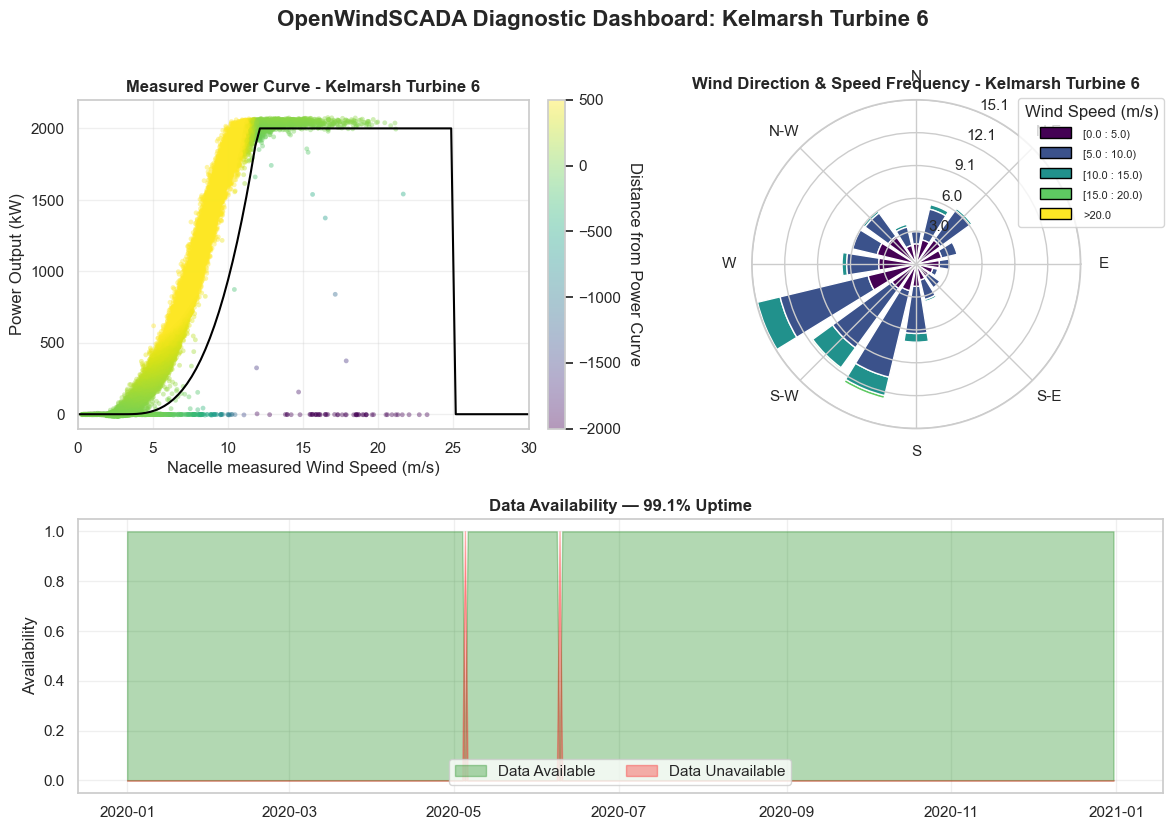


All available turbine dashboards successfully generated and saved to ..\notebooks\plots\dashboards!


In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt

# Add root directory to path
sys.path.append(str(Path.cwd().parent))

from src.data_loader import load_scada_data
from src.plotting import plot_turbine_diagnostic_dashboard

# 1. Define turbine IDs to process
turbine_ids = ['1', '2', '3', '4', '5', '6']

# Create output folder for saved portfolio images
output_dir = Path("../notebooks/plots/dashboards")
output_dir.mkdir(parents=True, exist_ok=True)

# 2. Loop through each turbine and generate dashboard
for t_id in turbine_ids:
    file_path = Path(f"../data/Turbine_Data_Kelmarsh_{t_id}_2020-01-01_-_2021-01-01.csv") # Adjust filename pattern to match your setup
    
    if file_path.exists():
        print(f"Generating diagnostic dashboard for Turbine {t_id}...")
        df = load_scada_data(file_path)
        
        # Generate dashboard figure
        fig = plot_turbine_diagnostic_dashboard(
            df, 
            turbine_name=f"Kelmarsh Turbine {t_id}",
            wind_col='Wind speed (m/s)',
            power_col='Power (kW)',
            dir_col='Wind direction (°)'
        )
        
        # Save high-resolution image for GitHub README / portfolio showcase
        save_path = output_dir / f"dashboard_turbine_{t_id}.png"
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()
    else:
        print(f"File for Turbine {t_id} not found at {file_path}. Skipping...")

print(f"\nAll available turbine dashboards successfully generated and saved to {output_dir}!")